In [56]:
# importer les packages 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import label_binarize 
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
import pickle 


In [57]:
file="train_u6lujuX_CVtuZ9i.xls"
data = pd.read_csv(file)
pd.set_option('display.max_rows',data.shape[0]+1)
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.000000,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.000000,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.000000,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.000000,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.000000,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.000000,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.000000,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.000000,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.000000,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.000000,349.0,360.0,1.0,Semiurban,N


In [58]:
pd.set_option('display.max_rows',10)

In [59]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [60]:
pd.DataFrame(data.isna().sum().sort_values()).transpose()

,Loan_ID,Education,ApplicantIncome,CoapplicantIncome,Property_Area,Loan_Status,Married,Gender,Loan_Amount_Term,Dependents,LoanAmount,Self_Employed,Credit_History
0,0,0,0,0,0,0,3,13,14,15,22,32,50


In [61]:
# renseigner les valeurs manquantes 
cat_data=[]
num_data=[]
for i,c in enumerate(data.dtypes):
    if c=="str":
        cat_data.append(data.iloc[:,i])
    else:
        num_data.append(data.iloc[:,i])

num_data=pd.DataFrame(num_data).transpose()
cat_data=pd.DataFrame(cat_data).transpose()

In [62]:
# Valeurs manquante des variables numeriques 
num_data

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849.0,0.0,NaN,360.0,1.0
1,4583.0,1508.0,128.0,360.0,1.0
2,3000.0,0.0,66.0,360.0,1.0
3,2583.0,2358.0,120.0,360.0,1.0
4,6000.0,0.0,141.0,360.0,1.0
...,...,...,...,...,...
609,2900.0,0.0,71.0,360.0,1.0
610,4106.0,0.0,40.0,180.0,1.0
611,8072.0,240.0,253.0,360.0,1.0
612,7583.0,0.0,187.0,360.0,1.0


In [63]:
# valeurs manquantes des variables catecorielles
cat_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,Urban,Y


In [64]:
# Remplacement des valeurs manquantes : 
cat_data=cat_data.apply(lambda x:x.fillna(x.value_counts().index[0]))
cat_data.isna().sum().any()

False

In [65]:
num_data.bfill(inplace=True)
num_data.isna().sum().any()


False

In [66]:
# traiter la variable target
target_value={'Y':1,'N':0}
target=cat_data['Loan_Status']
target=target.map(target_value)
target

0      1
1      0
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    0
Name: Loan_Status, Length: 614, dtype: int64

In [67]:
# coder les valeurs categorielles 
le=LabelEncoder()

for i in cat_data:
    cat_data[i]=le.fit_transform(cat_data[i])
cat_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,0,1,0,0,0,0,2,1
1,1,1,1,1,0,0,0,0
2,2,1,1,0,0,1,2,1
3,3,1,1,0,1,0,2,1
4,4,1,0,0,0,0,2,1
...,...,...,...,...,...,...,...,...
609,609,0,0,0,0,0,0,1
610,610,1,1,3,0,0,0,1
611,611,1,1,1,0,0,2,1
612,612,1,1,2,0,0,2,1


In [68]:
cat_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Loan_ID        614 non-null    int32
 1   Gender         614 non-null    int32
 2   Married        614 non-null    int32
 3   Dependents     614 non-null    int32
 4   Education      614 non-null    int32
 5   Self_Employed  614 non-null    int32
 6   Property_Area  614 non-null    int32
 7   Loan_Status    614 non-null    int32
dtypes: int32(8)
memory usage: 19.3 KB


In [69]:
# supprimer la colonne Loan_ID
cat_data.drop('Loan_ID',axis=1,inplace=True)


In [70]:
# Concatener cat_Data et num_data
data=pd.concat([num_data,cat_data],axis=1)
X=data.drop(['Loan_Status'],axis=1)
y=data['Loan_Status']


In [71]:
X

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,5849.0,0.0,128.0,360.0,1.0,1,0,0,0,0,2
1,4583.0,1508.0,128.0,360.0,1.0,1,1,1,0,0,0
2,3000.0,0.0,66.0,360.0,1.0,1,1,0,0,1,2
3,2583.0,2358.0,120.0,360.0,1.0,1,1,0,1,0,2
4,6000.0,0.0,141.0,360.0,1.0,1,0,0,0,0,2
...,...,...,...,...,...,...,...,...,...,...,...
609,2900.0,0.0,71.0,360.0,1.0,0,0,0,0,0,0
610,4106.0,0.0,40.0,180.0,1.0,1,1,3,0,0,0
611,8072.0,240.0,253.0,360.0,1.0,1,1,1,0,0,2
612,7583.0,0.0,187.0,360.0,1.0,1,1,2,0,0,2


# ANALYSE EXPLORATOIRE

In [72]:
# Loan_status 
pd.DataFrame(target.value_counts())

,count
Loan_Status,
1,422
0,192


<Axes: xlabel='Loan_Status', ylabel='count'>

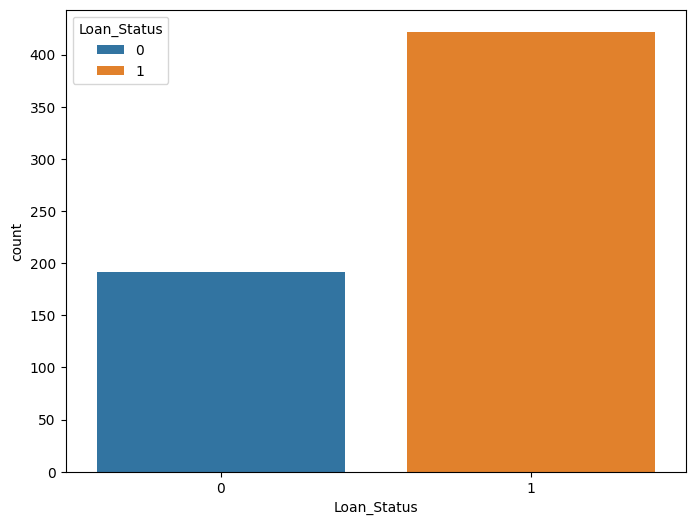

In [73]:
plt.figure(figsize=(8,6))
sns.barplot(pd.DataFrame(target.value_counts())
              ,x='Loan_Status',
                y='count', hue="Loan_Status")


c:\Users\DELL\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


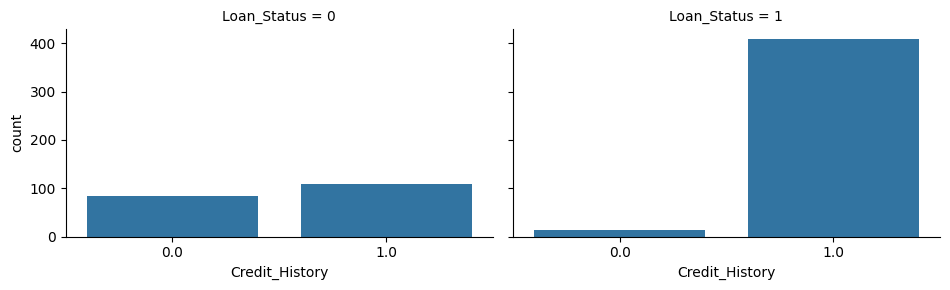

In [74]:
# Credit history 
grid=sns.FacetGrid(data,col='Loan_Status',height=3,aspect=1.6)
grid.map(sns.countplot,'Credit_History')

c:\Users\DELL\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


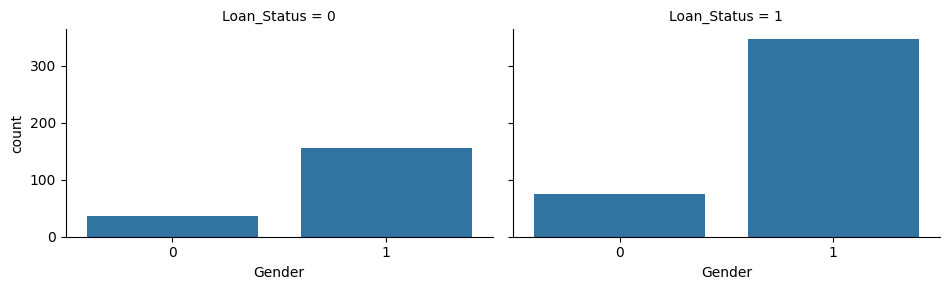

In [75]:
# Gender (1: male , 0:female) 
grid=sns.FacetGrid(data,col='Loan_Status',height=3,aspect=1.6)
grid.map(sns.countplot,'Gender')

c:\Users\DELL\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


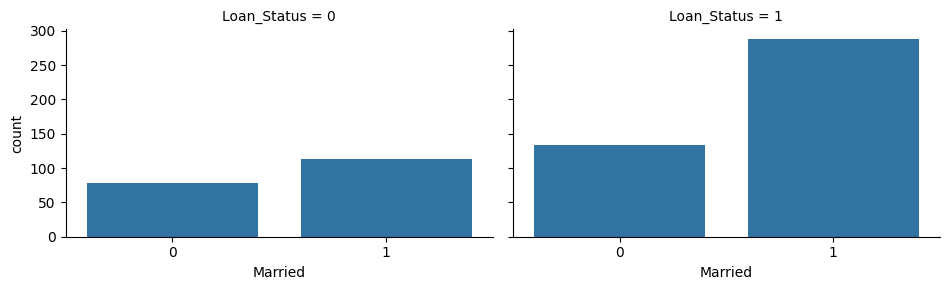

In [76]:
# Married (0: not married)
grid=sns.FacetGrid(data,col='Loan_Status',height=3,aspect=1.6)
grid.map(sns.countplot,'Married')

c:\Users\DELL\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


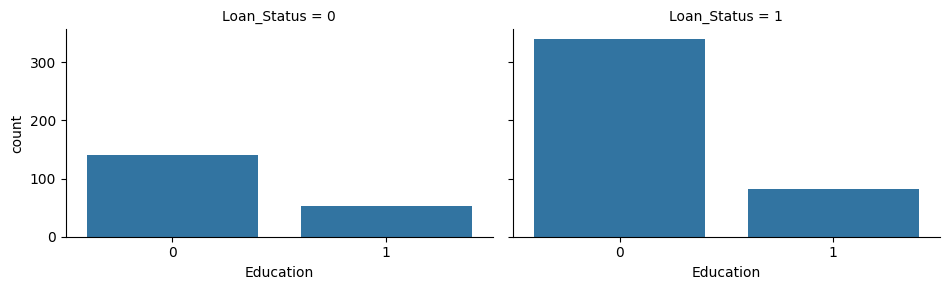

In [77]:
# Education (0:graduate)
grid=sns.FacetGrid(data,col='Loan_Status',height=3,aspect=1.6)
grid.map(sns.countplot,'Education')

c:\Users\DELL\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


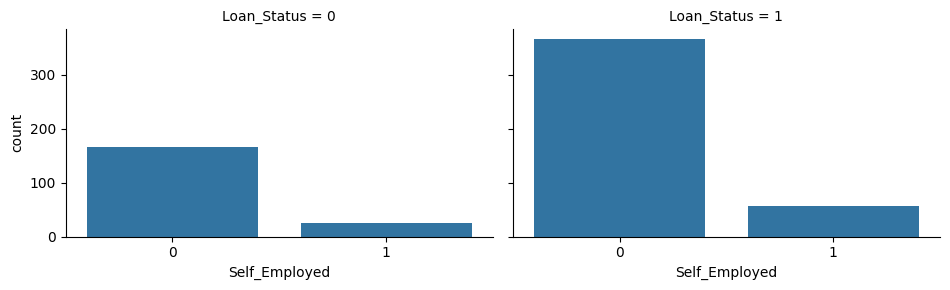

In [78]:
# Self_Employed (0: No,1:yes)
grid=sns.FacetGrid(data,col='Loan_Status',height=3,aspect=1.6)
grid.map(sns.countplot,'Self_Employed')

<Axes: xlabel='ApplicantIncome', ylabel='Loan_Status'>

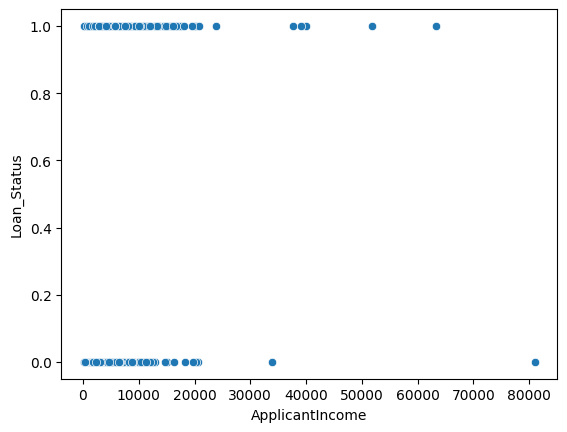

In [79]:
# Revenu du demandeur 
sns.scatterplot(data,x='ApplicantIncome',y='Loan_Status')

<Axes: xlabel='CoapplicantIncome', ylabel='Loan_Status'>

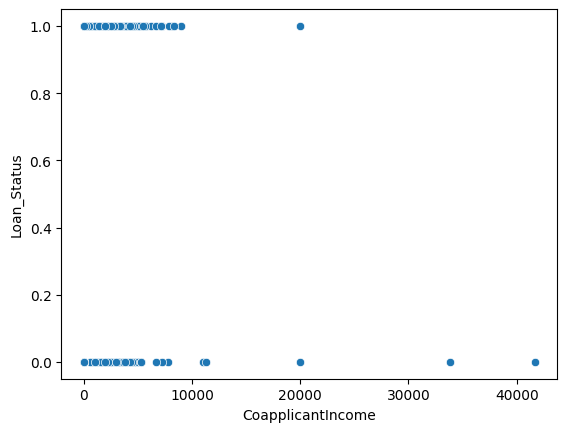

In [80]:
# Revenu du conjoint 
sns.scatterplot(data,x='CoapplicantIncome',y='Loan_Status')

In [81]:
data

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
0,5849.0,0.0,128.0,360.0,1.0,1,0,0,0,0,2,1
1,4583.0,1508.0,128.0,360.0,1.0,1,1,1,0,0,0,0
2,3000.0,0.0,66.0,360.0,1.0,1,1,0,0,1,2,1
3,2583.0,2358.0,120.0,360.0,1.0,1,1,0,1,0,2,1
4,6000.0,0.0,141.0,360.0,1.0,1,0,0,0,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...
609,2900.0,0.0,71.0,360.0,1.0,0,0,0,0,0,0,1
610,4106.0,0.0,40.0,180.0,1.0,1,1,3,0,0,0,1
611,8072.0,240.0,253.0,360.0,1.0,1,1,1,0,0,2,1
612,7583.0,0.0,187.0,360.0,1.0,1,1,2,0,0,2,1


# Machine Learning models 

In [82]:
# Division de la base de donnée :
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    shuffle=True, stratify=y)

print('X_train taille: ',X_train.shape)
print('y_train taille: ',y_train.shape)
print('X_test taille: ',X_test.shape)
print('y_test taille: ',y_test.shape)

X_train taille:  (491, 11)
y_train taille:  (491,)
X_test taille:  (123, 11)
y_test taille:  (123,)


In [83]:
# Models : Logistic Regression, KNN, DecisionTree
models={
    'log_model':LogisticRegression(),
    'knn_model':KNeighborsClassifier(),
    'dt_model':DecisionTreeClassifier()
}
# La fonction de precision 

def accu(y_true,y_pred,retu=False):
    acc= accuracy_score(y_true,y_pred)
    if retu:
        return(acc)
    else:
        print(f"la precision du modele est : {acc}")
# La fonction d'appication de modeles 

def train_test_eval(models,X_train,y_train,X_test,y_test):
    for name,model in models.items():
        print(name, ':')
        model.fit(X_train,y_train)
        accu(y_test,model.predict(X_test))
        print('-'*50)

train_test_eval(models,X_train,y_train,X_test,y_test)


log_model :
la precision du modele est : 0.8536585365853658
--------------------------------------------------
knn_model :
la precision du modele est : 0.6504065040650406
--------------------------------------------------
dt_model :
la precision du modele est : 0.6747967479674797
--------------------------------------------------


c:\Users\DELL\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [84]:
# Nouvelle base de donnée , en choisissant des vars pertinents 
X_2=X[["Credit_History",'Married',"CoapplicantIncome"]]
X_train, X_test, y_train, y_test = train_test_split(
    X_2, y, test_size=0.2, random_state=42,
    shuffle=True, stratify=y)
train_test_eval(models,X_train,y_train,X_test,y_test)

log_model :
la precision du modele est : 0.8536585365853658
--------------------------------------------------
knn_model :
la precision du modele est : 0.6991869918699187
--------------------------------------------------
dt_model :
la precision du modele est : 0.7073170731707317
--------------------------------------------------


In [85]:
#Develloper l'application de déploiement :(flask)
# model choisi : Regression logistic

Classifier=LogisticRegression()
Classifier.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [86]:
X_train

,Credit_History,Married,CoapplicantIncome
154,1.0,0,0.0
239,1.0,1,0.0
448,0.0,1,1710.0
471,0.0,1,1500.0
273,1.0,1,2223.0
...,...,...,...
222,1.0,0,2791.0
349,1.0,1,6250.0
26,1.0,1,2253.0
96,1.0,1,2302.0


In [87]:
# Enregistrer une image du modèle 
pickle.dump(Classifier,open('model.pkl','wb'))